# Report — Hydropower Unit Commitment (Tokke–Vinje)

**Course:** TDT4173 Modern Machine Learning in Practice — Course Project  
**Group number:** `[TODO]`  
**Kaggle team name:** `[TODO — must include the group number, e.g. "[34] A Fantastic Team"]`

| Full name | Student ID |
|-----------|------------|
| `[TODO]`  | `[TODO]` |
| `[TODO]`  | `[TODO]` |
| `[TODO]`  | `[TODO]` |

---

**How to read this report.** It is organised topically so every graded item has its own titled section, but it keeps one chronological thread running through it: *how one number — the micro-averaged ROC-AUC on an honest, time-based validation split — drove every decision we made.* At the start of each major section a short **“Where we were”** line places it on that timeline. The headline scoreboard (§0) is the whole project in one figure.

| Graded item / focused skill | Section |
|---|---|
| Domain knowledge · how the data was generated | §1 |
| 🧱 **Data manipulation & preparation** (time zones, daily→hourly joins, wide→long reshape, topology parsing) | §2 |
| 🔎 **Exploratory data analysis** (sanity · single features · pairs/groups · cleanup) | §3 |
| 🛠️ **Feature engineering** (extraction incl. the SHOP-LP feature · selection) | §4 |
| ≥2 predictor types · hyperparameters (each explained) | §5 |
| 🧪 **Model ensemble** | §6 |
| Validation strategy | §7 |
| 🔬 **Model interpretation** (gain importance · SHAP · partial dependence) | §8 |
| Results & leaderboard | §9 |
| Conclusion · what went well / what did not · limitations · reproducibility | §10 |

> **Graders:** this report is **not run**. Every number quoted is taken from our actual runs (`Short notebook 1/2.ipynb` outputs and the experiment cells referenced per section); every figure is embedded from those runs.

## 0. Executive summary & the scoreboard

We predict `P(ON)` for each of the 14 generating units in the Tokke–Vinje system, for every hour of a 168-hour scheduling case (2352 probabilities per case), scored with **micro-averaged ROC-AUC**. The labels are optimal schedules from SINTEF’s optimiser **SHOP**, so we treat the task as learning a fast **surrogate of SHOP**. We model one **long table** with a row per `(case, unit, hour)` and a single gradient-boosted classifier.

**The one-line result.** The decisive move was a feature built from the optimisation problem itself: for every case we solve a **linear relaxation of SHOP’s weekly problem** and give its solution to the model. Used *alone, with no learning*, the LP’s price-minus-water-cost margin already reaches AUC **0.960**; adding the LP features to the model lifts the validation AUC from **0.960 → 0.989**. That single feature group is worth **+0.029 AUC** — more than the choice of learner (<0.001), hyperparameters (<0.001) and ensembling (+0.00005) *combined*.

The whole project is one climb up this ladder; the rest of the report explains each rung — *why* we tried it and *why the number told us to keep it or stop*:

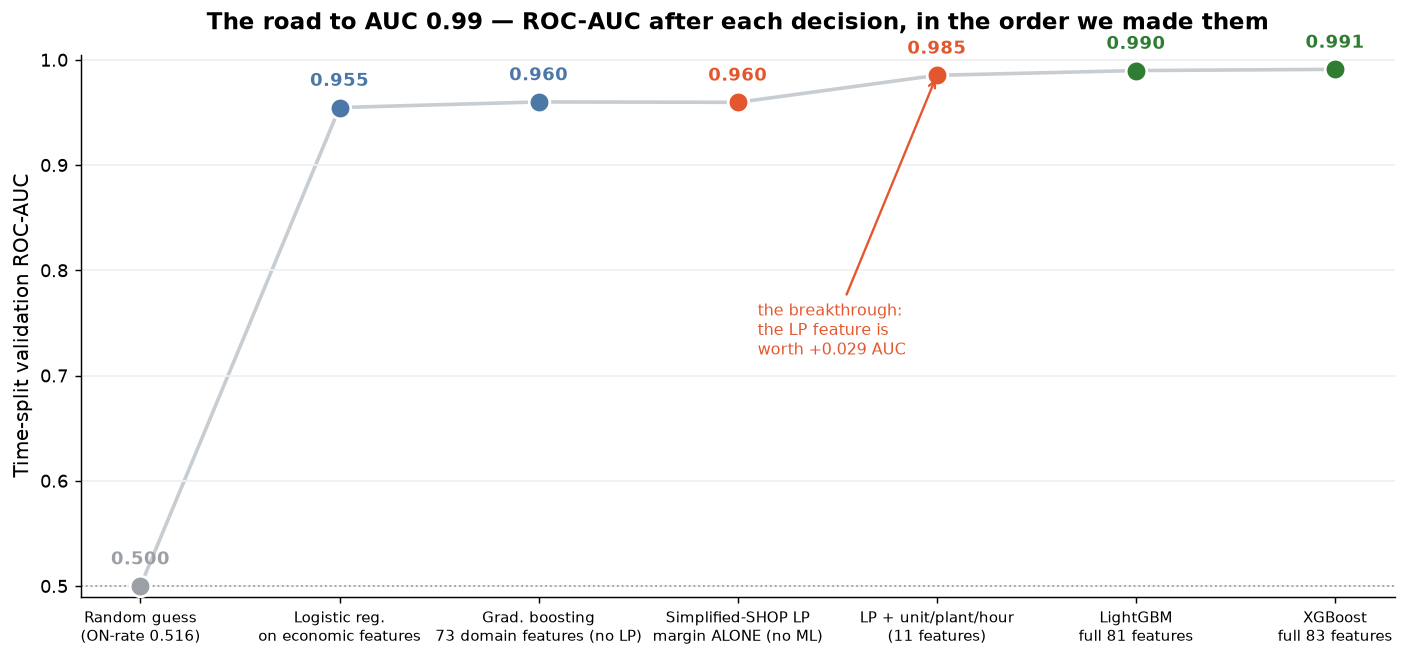

<sub>*Time-split validation ROC-AUC after each decision, in the order we made them. Grey = baseline · blue = a learner · orange = the optimiser-based (LP) feature · green = final models.*</sub>

| | Short notebook 1 | Short notebook 2 |
|---|---|---|
| Model | LightGBM | XGBoost |
| Features | 81 | 83 (+2 LP-gap features) |
| Time-split validation AUC | **0.98977** | **0.99092** |
| Public leaderboard | `[TODO]` | `[TODO]` |
| Private leaderboard | `[TODO]` | `[TODO]` |

On identical data LightGBM and XGBoost are equally good (0.989–0.990), ahead of random forest (0.986) and logistic regression (0.955). A rank-average ensemble adds nothing measurable (+0.00005), because the two boosters’ predictions are almost identical (Spearman ρ = 0.978). Our two selected Kaggle submissions are `[TODO: which two, and why]`.

## 1. Problem identification & domain knowledge

**For each unit and hour, unit commitment decides whether the unit is ON** (producing at least its minimum stable output `p_min`) **or OFF.** This is a real choice, not just “produce zero”: `p_min` ≈ 34 % of `p_max` for most units, and starts/stops cost money and cause wear, so schedules come in continuous blocks. We predict `P(ON)` for 14 units × 168 hours = **2352 unit-hours per case**.

**Why micro-averaged ROC-AUC, and why it frames everything.** The overall ON-rate is **0.516** — the classes are balanced — so accuracy would look reassuring but mislead. AUC rewards *ranking* unit-hours by `P(ON)`, which is exactly what a probability submission needs. A random guess scores 0.5 (rung 0 of the scoreboard); every decision below is judged by how it moves this one number on an honest validation split (§7).

**How the data was generated — the key insight.** The labels are **not human decisions**. They are optimal schedules from SINTEF’s short-term scheduler **SHOP v17.17.0** on the Tokke–Vinje model (17 reservoirs, 9 plants, 14 units, ≈1 GW). Each case (`Run No`) is one deterministic 168-hour optimisation starting at `starttime`, driven by hourly price and inflow (known for the whole week), initial reservoir volumes, the **water values** at `starttime + 7 days` (what water left at week-end is worth), rarely-active min-flow/min-volume constraints, and the topology. A new case starts every day, so consecutive cases overlap by 144 of 168 hours. **In principle the targets are a deterministic function of the inputs, so the ML task is to learn a fast surrogate of SHOP** — the idea the whole feature set (§4) is built on. Two caveats: the water values are *synthetic*, and the Hyljelihyl & Vatjern volumes are fixed at 50 % (no records), so those two series carry no information.

**The economic driver.** The **water value** is the opportunity cost of using water now rather than later. To first order a unit runs in hour *t* when the price exceeds the water value of the water it uses; since prices are known for the week and water is limited, SHOP fills the **highest-price hours** first. So the **rank of an hour’s price within its week** matters more than its absolute level. The system is a **cascade** (Kjela / Vesle Kjela / Songa → Totak → **Vinje** 3×100 MW → **Tokke** 4×107.5 MW → Bandak → Hogga), so downstream plants run on upstream releases and the units are not independent. Minimum load, start costs, storage/inflow and the (rarely binding) constraints shift this rule; identical units (Tokke G1–G4, Vinje G1–G3) are interchangeable, which caps how well any single one can be predicted.

**Six hypotheses, each with a pipeline consequence** (tested in §3, revisited in §8):

| # | Hypothesis | Pipeline consequence |
|---|---|---|
| H1 | `P(ON)` rises with the **within-week price rank** | use *relative* price features, not absolute levels |
| H2 | **price − water value** is predictive | build the spread (start, end, net) |
| H3 | high **fill fraction / inflow** raise ON-rates (spill avoidance) | add reservoir state & weekly inflow |
| H4 | strong **seasonal** pattern (weak hour-of-day) | calendar features |
| H5 | same-plant / cascade units **co-activate** | one shared model + unit-id, not 14 models |
| H6 | overlapping cases make **random K-fold leak** | validate on a **time-based** split |

## 2. Data manipulation & preparation 🧱

*Where we were: we understood the task; now we had to turn 8 raw files at 3 granularities into something a single classifier could learn from.*

- **Wide → long reshape.** We model a **long table**, one row per `(case, unit, hour)` with a binary target. That turns 2922 cases into **6 872 544 training rows** (and 1 705 200 test rows), so one classifier predicts `P(ON)` for every unit-hour — matching the micro-averaged metric directly. The wide submission is unit-major (`unit0 t0..t167, unit1 t0..t167, …`), so predictions pivot straight back to the 2352-column format at the end.
- **Three granularities, one timeline.** Price/inflow/constraints are hourly; volume and water value are *daily*. All series are UTC-stamped and every case starts at 00:00 UTC, so we strip the time zone, normalise daily series to midnight, and join hourly data by `starttime + hour` and daily data by date — **no time-zone drift**. Water value is read twice: at the case start, and at `start + 7 days` for the end-of-week value SHOP optimises against.
- **Topology parsing.** Static unit facts (`p_min`, `p_max`, start cost, intake/outlet reservoir, cascade position) are parsed from `topology.yaml` by walking the `connections` graph upstream to find each plant’s intake reservoir and downstream to find its outlet.

**Checkpoint:** a clean 6.9 M-row table with overall ON-rate 0.516. The question becomes: *where is the signal?* — which is why we looked (§3) before we modelled.

## 3. Exploratory data analysis 🔎

*Where we were: we had a trainable table but no signal yet. We deliberately explored before modelling, because the features to build depend on what the data actually does. (Covers ≥4 EDA items → avoids the −3.)*

### 3.1 Data sanity
- **No missing values, no duplicate timestamps**, every UC target is 0/1. The hourly series are regular except that from Oct 2025 the price file switches to 15-minute resolution — after the last test case, so irrelevant.
- The data covers the whole test period (last test case starts 2024-12-25; needs prices to 2024-12-31 23:00 and the water value for 2025-01-01).
- **Hyljelihyl & Vatjern volumes are exactly 50 % of `max_vol` every day (std = 0)** — confirming the dataset note that these are filled-in values, not measurements.
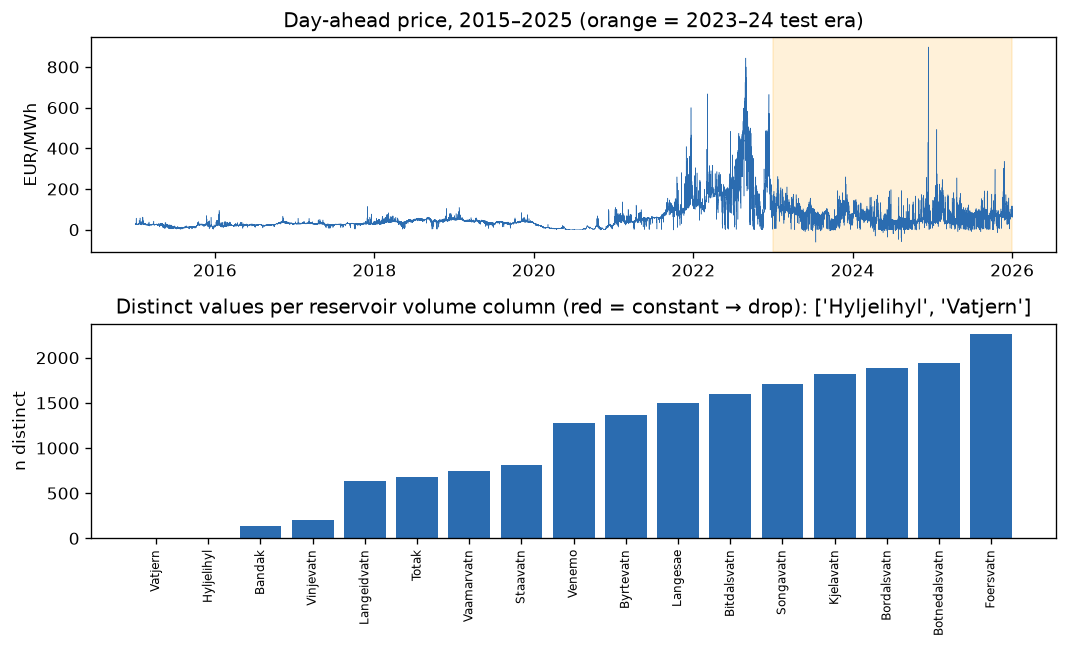

<sub>*Fig. 3.1 — Data-sanity checks across the eight tables.*</sub>

### 3.2 Individual features and the target
- **Price moved through three regimes.** Calm 2015–2020 (yearly mean 9–43 EUR/MWh), the 2021–2022 energy crisis (2022 mean 211, std 126), and a lower 2023–2024 *test* period (means 79 and 50). The test distribution is unlike the most recent training year — one reason we commit to *relative* price features.
- **Units are used very unequally.** ON-rates range 0.75 (Lio) → 0.26 (Vinje G3), and *identical* units differ (Tokke G1 0.67 vs G2 0.48), so SHOP has a systematic preference a `unit_id` feature can learn.
- **Schedules come in blocks:** units switch only 0.5–3.6 times per week. **H4** holds strongly for season, only weakly for hour-of-day — consistent with “what matters is price *relative to the week*, not clock time”.
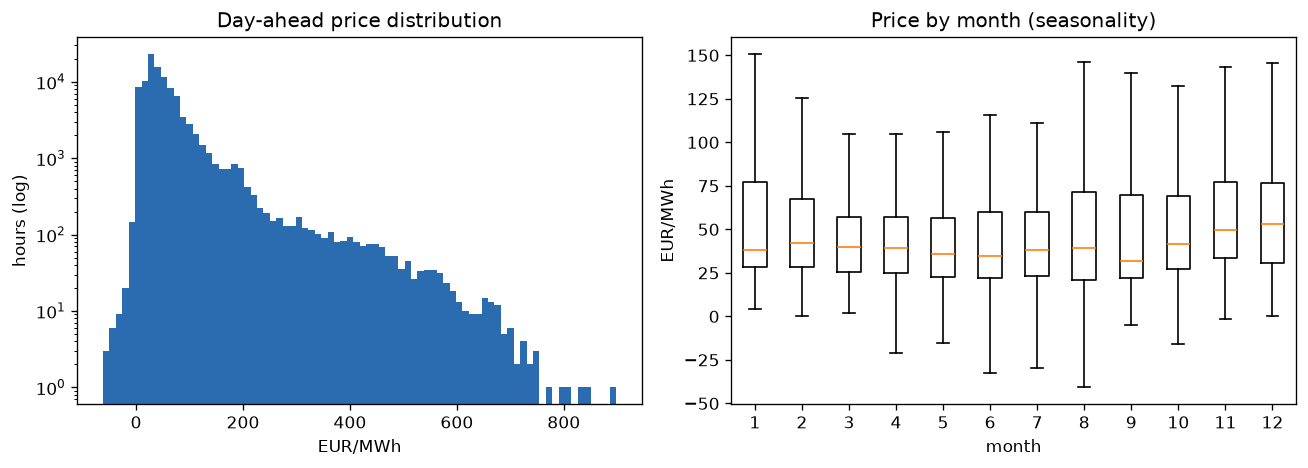

<sub>*Fig. 3.2 — Yearly price level: calm → 2021–22 crisis → lower test period.*</sub>
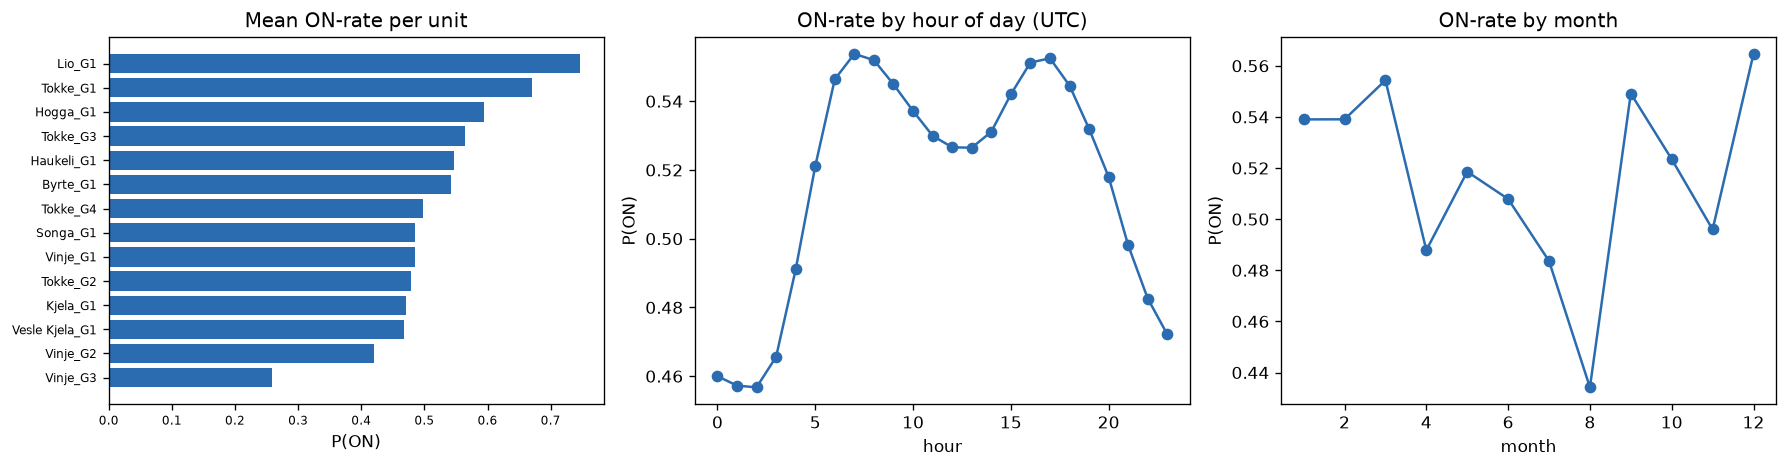

<sub>*Fig. 3.3 — ON-rate by unit and by month: strong seasonal structure, weak hour-of-day.*</sub>

### 3.3 Pairs and groups of features — the economic rule is visible directly
- **Price vs commitment (H1 ✓).** For every plant the ON-rate rises monotonically with the decile of the hour’s price within its week (Vinje 0.21 → 0.56; Tokke 0.40 → 0.72).
- **Price vs water value (H2 ✓).** The ON-rate steps up around a zero spread of price − net water value, from ~0.15–0.30 for clearly negative spreads to ~0.6 at +50 EUR/MWh. It falls again for extreme spreads (>100), 89 % of which are from the 2021–22 crisis — a single static spread does not capture that regime.
- **Reservoir state (H3 ✓).** ON-rate rises from 0.19 for the emptiest 5 % of intake reservoirs to 0.91 for the fullest; full reservoirs are drained to avoid spill.
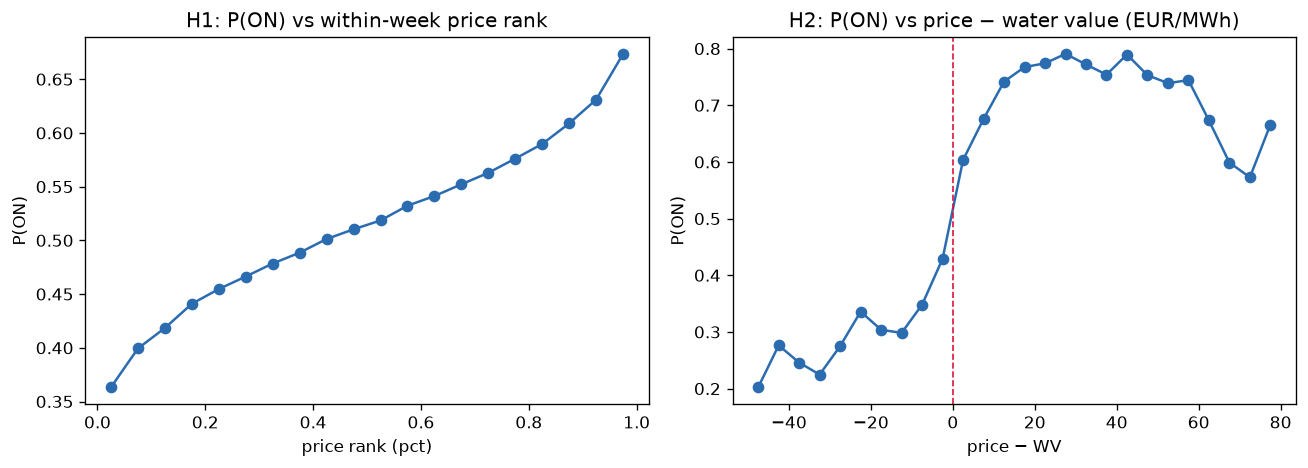

<sub>*Fig. 3.4 — (left) ON-rate vs within-week price decile [H1]; (middle) vs price−water-value spread [H2]; (right) vs reservoir fill [H3].*</sub>
- **Reservoir correlation.** Water values are strongly correlated across reservoirs (mean ρ = 0.88) since they share one market outlook; fill fractions much less (ρ = 0.48) — so we add *system means* rather than all 17 series.
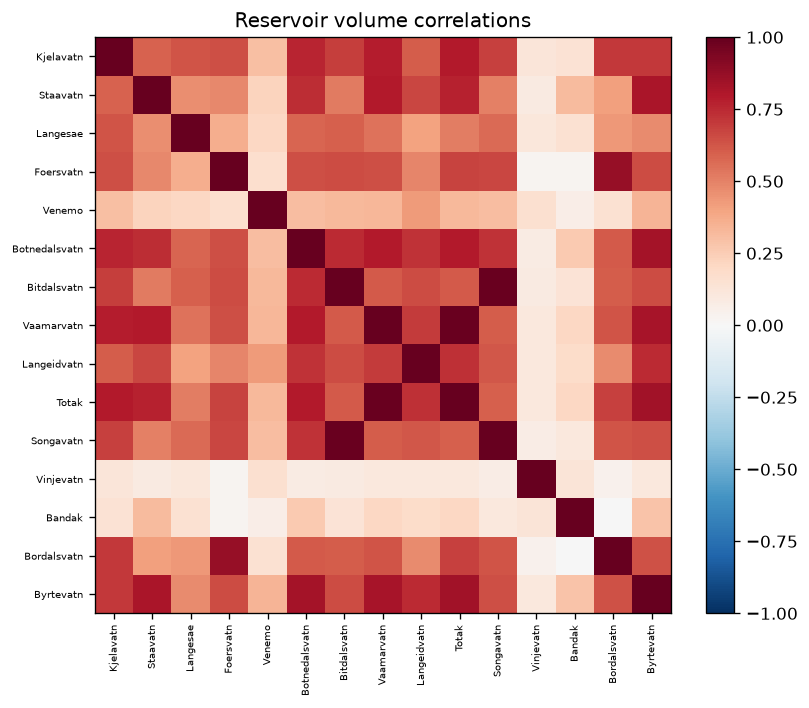

<sub>*Fig. 3.5 — Cross-reservoir correlation of water value vs fill fraction.*</sub>
- **Co-activation (H5 ✓).** Same-plant units have mean ON/OFF correlation 0.77 (vs 0.30 for other pairs); Tokke and Vinje correlate because Tokke runs on Vinje’s released water. This justifies one shared model with a unit-id feature over 14 separate models.
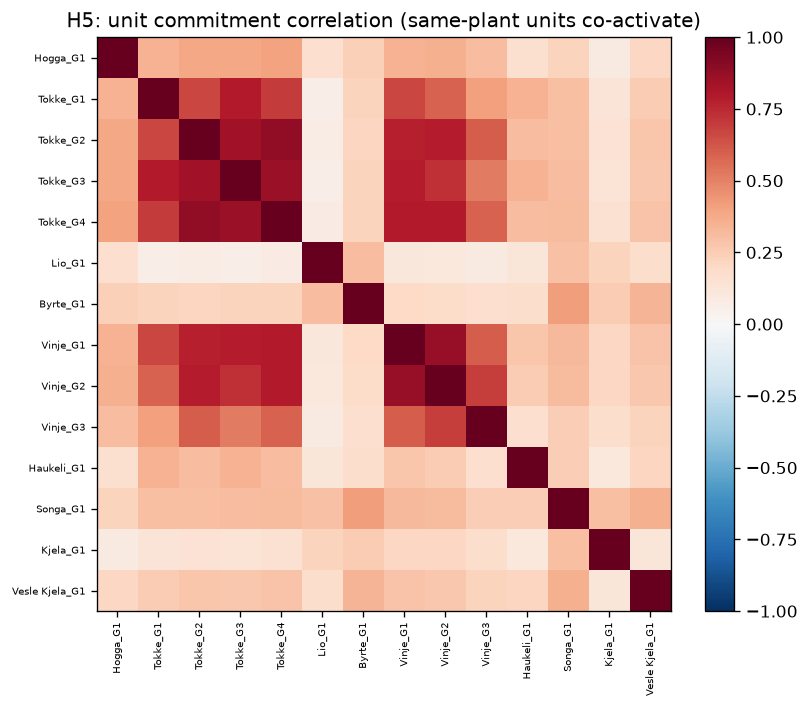

<sub>*Fig. 3.6 — Unit co-activation: same-plant and cascade-linked units move together.*</sub>
- **Overlapping cases (H6 ✓).** Two consecutive cases disagree on only **12.2 %** of shared unit-hours — they share **88 %** of labels. *This single finding dictated our validation strategy (§7):* a random split would let a model memorise a case’s near-twin.

### 3.4 Feature cleanup
Time zones removed and daily series normalised to midnight before joining; the constant Hyljelihyl/Vatjern volumes carry no information; constraints kept as raw hourly columns (redundancy handled by the filters in §4.3).

**Exit from EDA:** a ranked shopping list of features — all *relative* price signals, the price-vs-water-value spread, reservoir fill/inflow, unit identity — and a warning that honest validation must respect time.

## 4. Feature engineering 🛠️

*Where we were: EDA gave us a shopping list. This section is the heart of the project — the climb from 0.955 to 0.989 is almost entirely a feature-engineering story. (Avoids the −3.)* *Feature code: Short notebook 1 §3 and §3b; Short notebook 2 adds two LP features.*

### 4.1 Framing
The long `(case, unit, hour)` table gives ≈6.9 M training rows; one binary classifier predicts `P(ON)` for each. Static unit information is parsed from the topology YAML (§2).

### 4.2 Feature extraction — 81 features, grouped from the domain analysis

| Group | Examples | Why |
|---|---|---|
| Unit & topology | unit/plant id, `p_min`, `p_max`, start cost, units at plant, intake/outlet reservoir | units differ in size, cascade position, preference order (§3.2) |
| Calendar | hour-of-day, weekday, month, cyclic sin/cos, hour-in-horizon | seasonal patterns (H4) |
| Relative price | rank of the hour’s price in the week and day, deviation / z-score vs week mean, lags/leads, forward 3/6/12 h mean & max | SHOP fills the most expensive hours first (H1) |
| Water value & storage | price − water value (start, end, *net*), price/water-value ratio, fill fraction, weekly inflow / reservoir size, margin to min-volume, downstream state, system means | economic rule + spill avoidance (H2, H3) |
| “In the money” | share of the week’s hours with price > water value, and how far the hour’s rank sits above that cut-off | turns the rule into an estimate of how many hours a unit should run |
| Constraints | hourly min-flow / min-volume per restricted river/reservoir | can force units ON |
| ON-rate priors | historical `P(ON)` per unit×hour-of-day and unit×month, **computed on the fit fold only** | strong, leak-free baseline |
| **LP features (simplified SHOP)** | per case, solve a linear relaxation of SHOP’s weekly problem (water balance through the topology, reservoir & discharge limits, constraints, end-of-week water values) → plant discharge, unit load, and price − the LP’s marginal water cost | hands the model the optimiser’s own trade-off |

**The chronology of the climb:**
1. **Domain features + a linear model → AUC 0.95462.** First real signal; the economics are learnable. But logistic regression scored *below the raw LP margin it was given* — a hint the next win was about model *shape*, not more features.
2. **Same features + gradient boosting (no LP) → 0.95996.** Trees capture the step-at-zero and the unit×state interactions a linear model cannot.
3. **The breakthrough.** Because the labels come from an optimiser, we built a cheap copy of it: a **linear relaxation of SHOP** solved per case with HiGHS/SciPy. *Used alone as a score, with no learning, the LP margin already reaches AUC 0.960* (0.95577 on train). Feeding the LP group to the model lifts it to **0.989**.

**Short notebook 2** adds two features aimed exactly at the LP→SHOP gap: `lp_commit_hat` — a `p_min`-aware integer rounding of the LP (AUC 0.899 alone) — and `lp_run_frac`, the share of three LP solves (end-of-week water values scaled 0.9 / 1.0 / 1.1) in which the plant stays economic, which flags the marginal hours where labels are hardest.

### 4.3 Feature selection

| Variant | # features | Validation AUC |
|---|---|---|
| All features (Short notebook 1) | 81 | **0.98919** |
| After near-constant + correlation filter | 66 | 0.98910 |
| Without LP features | 73 | 0.95996 |
| **LP features + unit/plant/hour only** | **11** | **0.98525** |

- A **near-constant filter** (>99 % one value) drops only `minvol_start`; a **correlation filter** (|ρ|>0.98) drops 14 redundant features. The filtered 66-feature set scores 0.98910 vs 0.98919 — the removed features carried no extra information *and did no harm*, so we **kept the full set** (the filtered set trains in 55 s vs 85 s and would be the choice if runtime mattered).
- **The LP effect dominates everything.** Removing the LP drops the AUC 0.989 → 0.960; the LP group plus three identity columns (11 features) already reaches 0.985. This is by far the largest single effect of any feature group.
- **Group ablation (before the LP)** over three rolling yearly folds moved the mean AUC by less than the measured ±0.003 seed noise, so we did *not* add further candidate groups (end-of-week volume, daily release, block features, unit order) — keeping the feature set smaller.

## 5. Modeling — multiple predictor types

*Where we were: signal found. Now — which learner, and does it even matter? (≥2 types → avoids the −3.)*

### 5.1 Framing and alternatives
We use the long `(case, unit, hour)` framing with a single classifier. We considered **one model per unit** (14 models — each sees far less data, and units share most structure a unit-id captures) and a **sequence model** (1D-CNN/RNN over the 168 hours — the forward/backward price windows and LP features already give trees that context at far lower cost). Given the time available we pursued neither.

**Experimental setup.** To compare many models affordably, §4.3–§8 use every 4th training case (731 of 2922 cases, 1.72 M rows) on the same time split as the short notebooks (fit `Run No ≤ 2483`, validate the remaining 110 cases, Oct 2021 – Dec 2022). The short notebooks train on all 2922 cases.

### 5.2 Predictors (same 81 features, identical data)

| Model | Validation AUC | Fit time | Notes |
|---|---|---|---|
| LP margin alone (no learning) | 0.95960 | – | physical baseline |
| Logistic regression | 0.95462 | 32 s | linear; worse than its own LP-margin input |
| Random forest | 0.98637 | 66 s | 200 trees, `min_samples_leaf=50`, 25 % rows/tree |
| XGBoost | **0.98985** | 189 s | 879 rounds (early stopping) |
| LightGBM | 0.98919 | 85 s | 604 rounds (early stopping) |
| *Short notebook 1: LightGBM, all data* | *0.98977* | | 484 rounds, 81 features |
| *Short notebook 2: XGBoost, all data* | ***0.99092*** | | 569 rounds, 83 features |

Logistic regression cannot represent the step-at-zero and interactions; trees gain ~0.03, and the two gradient-boosting libraries another ~0.003 by fitting the residuals where the hard, marginal hours live. **LightGBM and XGBoost are within 0.0007 of each other** — once the features are right, the learner barely matters. LightGBM trains about twice as fast.

### 5.3 Hyperparameters — and how they were chosen
Hard-coded in the short notebooks: **LightGBM** `learning_rate=0.05, num_leaves=255, min_child_samples=200, feature_fraction=0.8, bagging_fraction=0.8`; **XGBoost** `learning_rate=0.05, max_depth=8, min_child_weight=50, subsample=0.8, colsample_bytree=0.8, reg_lambda=1, tree_method="hist"`; the **round count** is set by early stopping (patience 100, max 1200) on the time-split validation, then the model is refit on all data with that count.

**How we found them.** Starting from capacity reasoning (6.9 M rows support deep trees; row/column subsampling and a minimum leaf size regularise them), we grid-searched capacity and regularisation at `learning_rate=0.1`. **All 9 LightGBM settings fell within 0.001 of each other and all 6 XGBoost settings within 0.0006 — smaller than the ±0.003 seed-to-seed noise.** The surface is flat, so we kept our capacity-reasoned starting values; the number said tuning here was not worth chasing.

## 6. Model ensemble 🧪

*Where we were: two strong learners. The natural next question — does combining them help?*

Random forest and gradient boosting are themselves ensembles of hundreds of trees. On top, we tested combining *different* models by **rank-averaging** their predictions (ROC-AUC depends only on order, so ranks also cancel calibration differences):

| Combination | Validation AUC |
|---|---|
| LightGBM alone | 0.98919 |
| XGBoost alone | 0.98985 |
| LightGBM + XGBoost, equal weights | 0.98980 |
| LightGBM + XGBoost, best (tuned) weight 0.2/0.8 | 0.98990 |
| + random forest, equal weights | 0.98951 |

**The number said no.** The best blend beats XGBoost alone by **+0.00005** — and that weight was tuned on the validation set itself, so the true gain is smaller still; adding random forest makes it *worse*. The reason is in the correlations: LightGBM and XGBoost rank the rows almost identically (**Spearman ρ = 0.978**) because they learn the same function from the same features, so their errors sit in the *same* hard hours — and an ensemble only helps when members err differently. **Decision:** submit two single models (one per short notebook) for genuine diversity rather than a blend.

## 7. Validation strategy

*Where we were: every decision above rests on one AUC — so is that number honest? EDA (H6) warned it might not be.*

**Time-based split.** Both short notebooks fit on `Run No ≤ 2483` (2015 → Oct 2021) and validate on the rest (Oct 2021 → Dec 2022), mirroring the real train(2015–22)→test(2023–24) shift. The validation score drives early stopping and *every* model/feature decision; the final model is refit on all cases. ON-rate priors are computed on the fit fold only, so no validation label leaks into a feature.

**Why not random K-fold** — measured with the same model and data:

| Split | Validation AUC |
|---|---|
| Random split of **rows** | 0.99977 |
| Random split of **cases** | 0.99314 |
| **Time split (ours)** | **0.98919** |

A random row split reports a near-perfect 0.9998 because the same unit-hour, with nearly identical inputs, sits in a neighbouring training case — memorisation, not generalisation. Even a split by whole cases overestimates by 0.004.

- **Purge gap:** dropping validation cases within 7/14 days of the split changes the AUC by ≤0.00014 — boundary leakage is negligible.
- **Stability:** the validation period is hard (it covers the 2022 crisis; validation ON-rate 0.355 vs 0.548 in training), yet AUC stays 0.975–0.996 across quarters; per-unit it ranges 0.954 (Haukeli) to 0.999 (Byrte).
- **Public vs private LB:** we select final submissions on the time-split score, not public rank. A covariate-shift check (Short notebook 2) confirms no feature drifts by >1 training std and our strongest features are *scale-free* (within-week rank, LP margins), robust to the 2022→2023 price change. `[TODO: compare validation AUC with public LB once known]`

## 8. Model interpretation 🔬

*Where we were: AUC ≈ 0.99 — but is it right for the right reasons? We check the model learned the economics, not an artefact. (Avoids the −3.)* We interpret the LightGBM model (81 features) three ways, and compare it to the same model trained **without** the LP features.

**Gain importance — the LP features are 74 % of total gain.** `lp_unit_load` alone is 47 %; the top five are LP features plus `unit_id`. *Without* the LP, the water-value/storage group takes over (~75 % of gain) — the model rebuilds the same price-vs-water-value reasoning from simpler features, less precisely. The LP does that reasoning per case and hands the model the result.
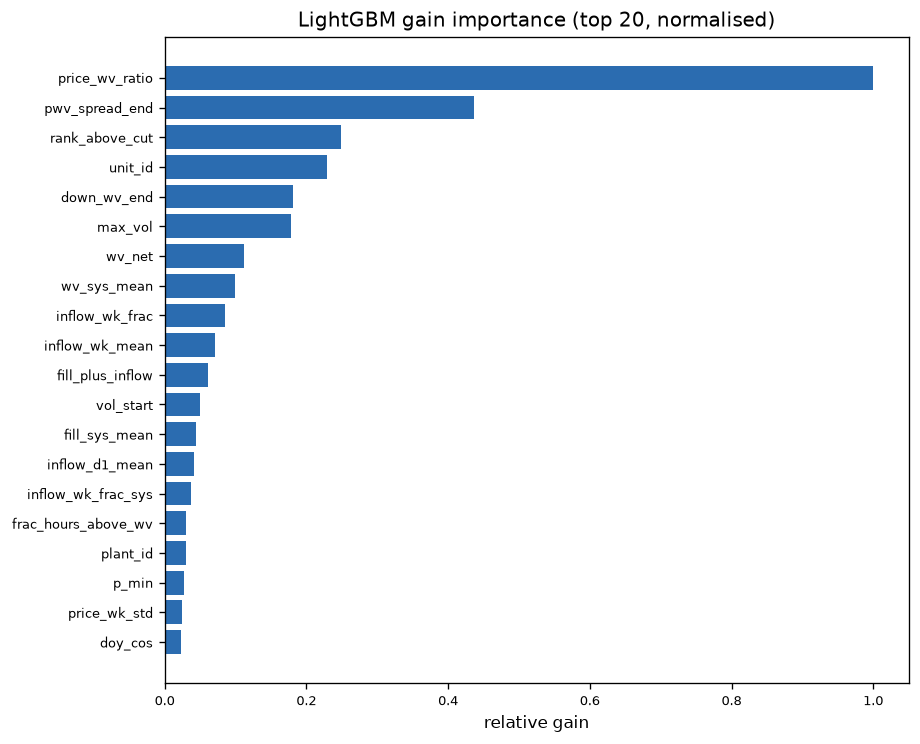

<sub>*Fig. 8.1 — LightGBM gain importance, with vs without the LP features.*</sub>

**SHAP — the sign of the economics is exactly right.** A positive LP margin (price above the LP’s marginal water cost) pushes strongly towards ON (up to +4 log-odds); neighbouring-hour margins let the model bridge short dips, matching the block structure (start costs). `unit_id` has a wide two-sided spread — the same inputs mean different things for different units.
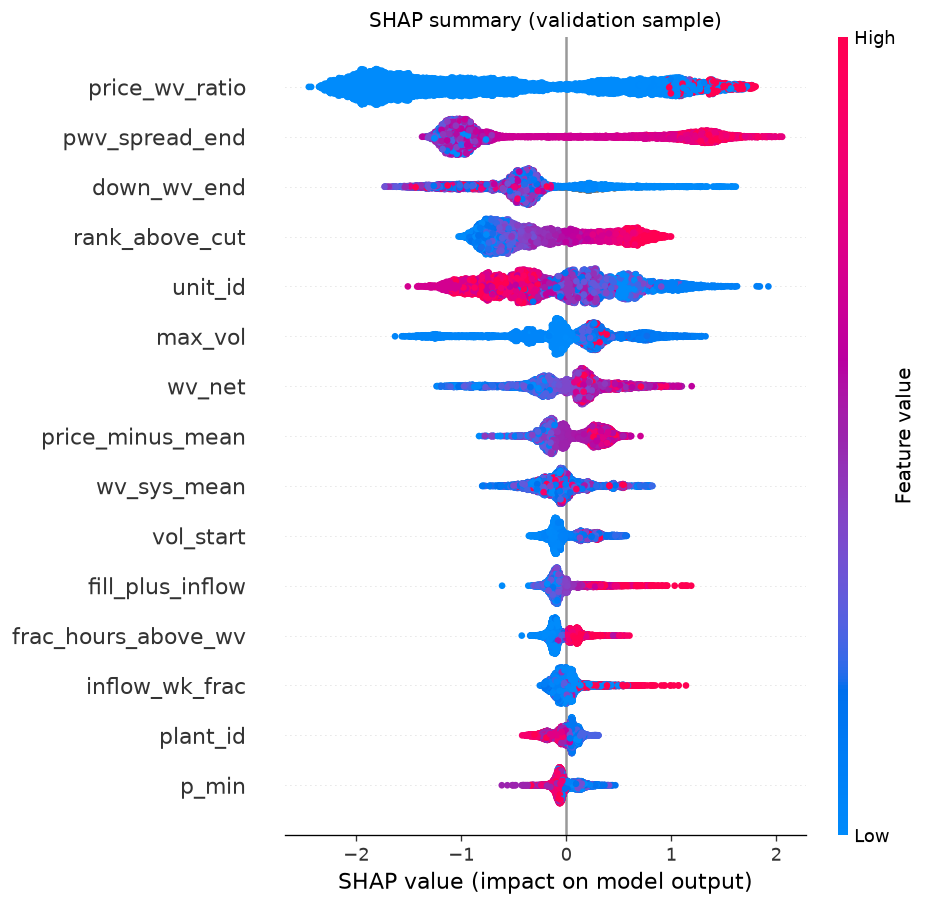

<sub>*Fig. 8.2 — SHAP values over 5000 validation rows.*</sub>

**Partial dependence — the economic rule is a visible step.** `lp_margin` shows a sharp step at zero (P(ON) ≈ 0.28 → 0.44): the model learned “run when price beats the water value”. With the LP present, the `price_rank` and `fill_frac` curves flatten because that information is already inside the LP margin.
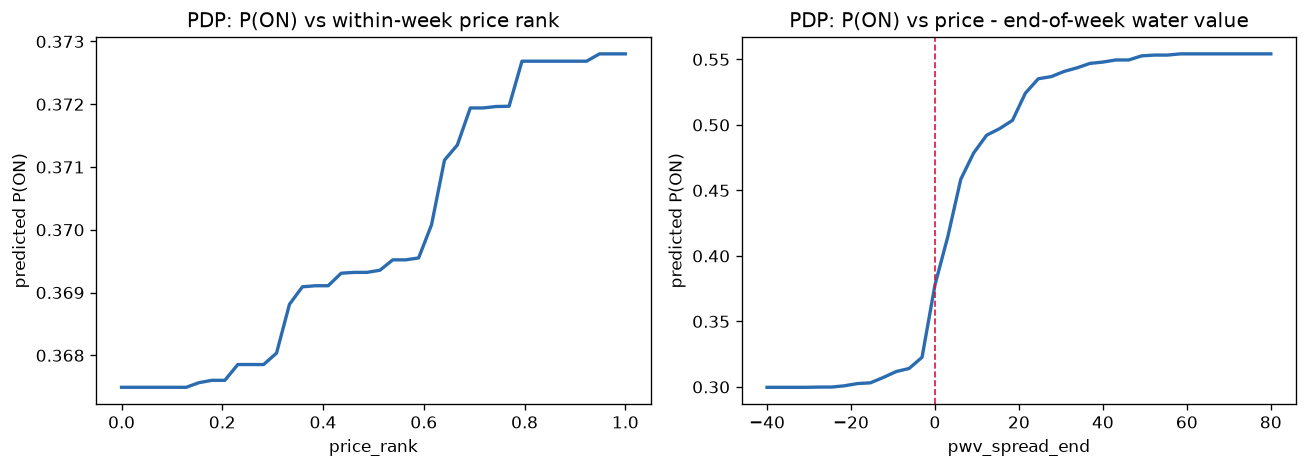

<sub>*Fig. 8.3 — Partial dependence on lp_margin, price_rank, fill_frac, pwv_spread_net.*</sub>

**The loop closes.** All three methods agree the model learned SHOP’s logic — run in the most expensive hours of the week, when price beats the water value, in continuous blocks — and gets it mostly from the LP relaxation of SHOP’s own problem. Where it is weakest is *explainable*: the worst unit is Haukeli (AUC 0.954), whose intake reservoir Vatjern is one of the two with a filled-in constant volume (§3.1), so the model cannot see its real storage state.

## 9. Results & leaderboard

### 9.1 Kaggle
| Submission | Notebook | Validation AUC | Public LB | Private LB | Selected |
|---|---|---|---|---|---|
| LightGBM, 81 features | Short notebook 1 | 0.98977 | `[TODO]` | `[TODO]` | `[TODO]` |
| XGBoost, 83 features | Short notebook 2 | 0.99092 | `[TODO]` | `[TODO]` | `[TODO]` |

Virtual Teams beaten: `[TODO]`.

### 9.2 The four results that summarise the project
1. **Features matter more than the learner.** The LP features add 0.029 AUC (0.960 → 0.989); switching LightGBM↔XGBoost changes it by <0.001, and tuning by <0.001.
2. **Gradient boosting is the best family** (≈0.989–0.990), ahead of random forest (0.986) and logistic regression (0.955).
3. **Ensembling does not help here** (+0.00005 at best) — the two boosters make the same errors.
4. **Honest validation matters** — a random split would have reported 0.9998 instead of 0.989.

## 10. Conclusion — what went well, what did not, limitations & reproducibility

### ✅ What went well
- **Reframing the task as learning a surrogate of the optimiser.** This one idea made the LP feature obvious and was worth **+0.029 AUC** — the biggest move in the project by an order of magnitude.
- **EDA that steered the pipeline.** Every hypothesis (H1–H6) became a concrete decision: relative price features, system-mean water value, one shared model, and the time-based split.
- **Letting the number decide, both ways.** The AUC told us to *keep* the LP (loudly) and to *stop* on selection, tuning and ensembling (all within noise) — which saved compute and avoided overfitting the validation set.
- **Honest validation** (catching the 0.9998-vs-0.989 gap) and **two genuinely different learners** that agree.

### ❌ What did not work (negative results worth stating)
- **Ensembling** of LightGBM/XGBoost/RF: no measurable gain (ρ = 0.978; +0.00005 at best); adding RF made it worse.
- **Hyperparameter tuning:** flat within seed noise (all settings within 0.001; noise ±0.003).
- **Extra feature groups before the LP** (end-of-week volume, daily release, block features, unit order): within seed noise, so not added.
- **Feature selection:** 15 fewer features scored the same — useful for runtime, not score.
- **Logistic regression** did worse than its own LP-margin input — model shape can waste a good feature.

### ⚠️ Limitations
- **The LP is a relaxation** (it drops the ON/OFF integers, start costs, `p_min`, head efficiency); the residual errors live in the marginal hours. Short notebook 2’s integer-rounding and water-value-robustness features target exactly this.
- **Identical units are partly interchangeable**, capping per-unit accuracy.
- **Data limits:** synthetic water values and two constant-volume reservoirs hurt Haukeli in particular (AUC 0.954). **Report experiments use a subset** (every 4th case) to keep the many comparisons affordable; the short notebooks use all data and agree.
- **A predicted schedule is not a feasible schedule** — hour-by-hour probabilities can break minimum-load/start constraints. In practice (SINTEF’s InterOpt project) these would warm-start or constrain SHOP, not replace it.

### 🔁 Reproducibility
- *Short notebook 1* reproduces the LightGBM submission, *Short notebook 2* the XGBoost submission. `[TODO: state which gives our best Kaggle score]` Both run **offline from raw data** in `DATA_DIR`, with fixed seeds, inside the 12 h / 4-core / 32 GB budget (the LP takes ≈6 min in NB1, ≈21 min in NB2). Each writes `submission.csv` with columns identical to `sample_submission.csv`.
- This report quotes the same measured numbers from those runs; figures are embedded from `artifacts/`.